**15.071 The AI Edge** · Project 1: Predictive AI · Fall 2026 · MIT Sloan School of Management

Team: Audrey DeVault, Paul Bustarret, Charles Loriot, Sara Alafifi

---

# Slide figures: the queue's speculative flood

Investor-deck charts. Figures 12–13 are versions of [01_charles_tabular_models](01_charles_tabular_models.ipynb)'s figure 01 for the queue-flood slide; 14–15 redraw the money slide from the current, signed-off data:

| Figure | Shows |
|---|---|
| `12_queue_entries.png` | Projects entering the queue each year |
| `13_build_rate.png` | Share of those projects built within 5 years |
| `14_wasted_per_mw.png` | Slide 6: money lost on failed projects per MW built, top 25 a year (random vs. rule of thumb vs. model) |
| `15_top25_share_built.png` | Slide 6: share of the model's top 25 capacity built, against the 28% break-even |

Same labeled projects as the pipeline (`data.modeling_table`, six operators, entries 2005–2020). Figures 12–13 fit nothing. Figures 14–15 refit the LASSO and the historical-rate rule at their **frozen** settings (`models.selected`) on 2005–2014 and score 2015–2018 only, as notebook 01 does; the 2019–2020 test cohort is never scored. Styled to match the deck (Arial, the deck's background and blue, no train/test shading).

## Setup

In [1]:
import logging, os, sys
from pathlib import Path

# The project root is the folder holding pyproject.toml, found by walking up
# from wherever this notebook is opened.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from queue_risk import config, data

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # falls back if Arial is missing
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)

# Deck palette (Queue Risk AI slides)
BG, INK, MUTED, BLUE, BAR, GRID = "#F4F3EE", "#1B2430", "#5A6270", "#2A6FDB", "#C9CDD3", "#DDDBD3"
plt.rcParams.update({"font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 13,
                     "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED})

## The numbers

Entries and the 5-year build rate by entry year. These are the values both charts plot.

In [2]:
projects = data.modeling_table(data.load_raw_queue())   # built within config.HORIZON = 5 years
by_year = projects.groupby("q_year")["built"].agg(projects="size", rate="mean")
years = by_year.index.astype(int).tolist()
n = by_year["projects"].tolist()
rate = (100 * by_year["rate"]).tolist()
LAST = years[-1]

print(f"{len(projects):,} labeled projects, entries {years[0]}–{LAST}")
print(f"Entries: {n[years.index(2014)]:,} in 2014 -> {n[-1]:,} in {LAST} ({n[-1] / n[years.index(2014)]:.1f}x)")
print(f"Built within {config.HORIZON} years: {rate[years.index(2014)]:.0f}% (2014) -> {rate[-1]:.0f}% ({LAST})")
by_year.assign(rate=(100 * by_year["rate"]).round(1)).rename(columns={"rate": "built within 5y (%)"}).T

10,685 labeled projects, entries 2005–2020
Entries: 365 in 2014 -> 1,721 in 2020 (4.7x)
Built within 5 years: 20% (2014) -> 3% (2020)


q_year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
projects,211.0,328.0,426.0,557.0,384.0,716.0,589.0,193.0,251.0,365.0,550.0,903.0,960.0,1071.0,1460.0,1721.0
built within 5y (%),23.2,15.5,6.6,6.1,8.9,7.4,6.5,21.2,19.1,20.0,14.5,10.3,7.7,5.7,4.6,3.0


In [3]:
def deck_axes(title):
    """One chart in the deck's style: no y-axis, left-aligned title, four year ticks."""
    fig, ax = plt.subplots(figsize=(6.4, 3.8), facecolor=BG)
    ax.set_facecolor(BG)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(length=0)
    ax.set_xticks([2005, 2010, 2015, 2020])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=15, color=INK, pad=14)
    return fig, ax


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200, facecolor=BG)
    print("saved reports/figures/" + name)
    plt.show()

## Chart 1: projects entering the queue each year

saved reports/figures/12_queue_entries.png


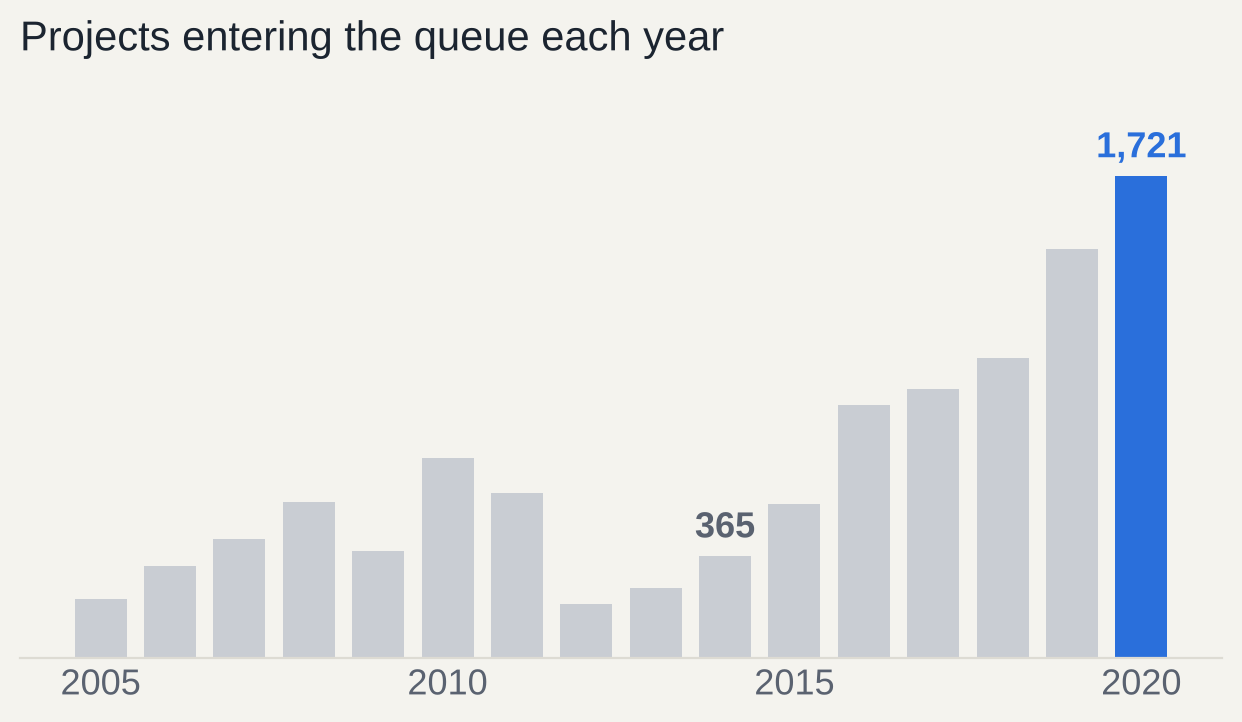

In [4]:
fig, ax = deck_axes("Projects entering the queue each year")
ax.bar(years, n, color=[BLUE if y == LAST else BAR for y in years], width=0.75)
for y, v in zip(years, n):
    if y in (2014, LAST):
        ax.text(y, v + 40, f"{v:,}", ha="center", va="bottom", fontsize=13,
                color=BLUE if y == LAST else MUTED, fontweight="bold")
ax.set_ylim(0, max(n) * 1.18)
save(fig, "12_queue_entries.png")

## Chart 2: share built within 5 years

The 2012–2014 bump is real: entries dipped in those years and a larger share of them was built.

saved reports/figures/13_build_rate.png


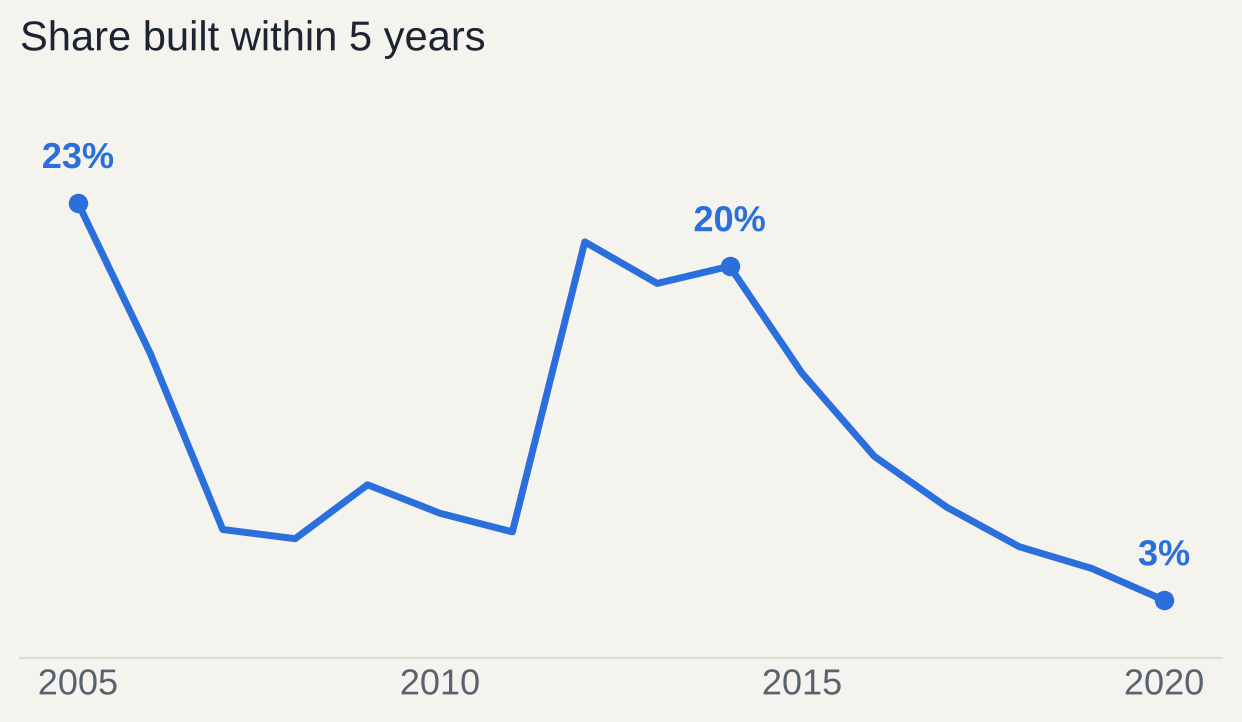

In [5]:
fig, ax = deck_axes(f"Share built within {config.HORIZON} years")
ax.plot(years, rate, color=BLUE, lw=2.5)
marks = (years[0], 2014, LAST)
ax.scatter(marks, [rate[years.index(y)] for y in marks], color=BLUE, zorder=3, s=36)
for y in marks:
    v = rate[years.index(y)]
    ax.text(y, v + 1.4, f"{v:.0f}%", ha="center", va="bottom", fontsize=13, color=BLUE, fontweight="bold")
ax.set_ylim(0, max(rate) * 1.25)
ax.set_xlim(years[0] - 0.8, LAST + 0.8)
save(fig, "13_build_rate.png")

## The money slide: waste per MW built, and the model's top 25

Same method as notebook 01's "Wasted development spend per built MW" and "top 25" sections, on the current data (odd rows excluded, team decision Nov 24) and the frozen model settings:

- **Waste per MW built:** back the top 25 projects of each 2015–2018 cohort, ranked by chance of being built × MW; charge `config.DEV_COST_RANGE_USD` mid ($4.95M) per failed project; divide by MW built. Random = expected value of 25 random picks.
- **Top-25 share built:** the model's top 25 by chance of being built (probability only), MW-weighted share built within 5 years, against the 28% median break-even (`strategy.py`).

In [6]:
import numpy as np
from queue_risk import features, impact
from queue_risk.models import selected

X, y = features.build_features(data.load_raw_queue(), projects)
y = np.asarray(y)
yr = projects["q_year"].to_numpy()
mw = projects["mw_total"].fillna(0).to_numpy()
train = yr <= 2014
scores = {k: selected(name, X[train]).fit(X[train], y[train]).predict_proba(X)[:, 1]
          for k, name in [("rule", "Historical rate (region x tech)"), ("model", "LASSO logistic")]}

COST, K, OOT = config.DEV_COST_RANGE_USD[1], 25, range(2015, 2019)
tot = {"Random picks": [0.0, 0.0], "Rule of thumb": [0.0, 0.0], "Our model": [0.0, 0.0]}
share = {}
for t in OOT:
    i = yr == t
    yy, m = y[i], mw[i]
    tot["Random picks"][0] += COST * K * (1 - yy.mean())
    tot["Random picks"][1] += K * (m * yy).mean()
    for name, s in [("Rule of thumb", scores["rule"][i] * m), ("Our model", scores["model"][i] * m)]:
        r = impact.portfolio(yy, m, s, K, COST)
        tot[name][0] += r["wasted_usd"]
        tot[name][1] += r["mw_built"]
    top = impact.backed(scores["model"][i], K)
    share[t] = 100 * (m[top] * yy[top]).sum() / m[top].sum()
waste = {k: w / b / 1e3 for k, (w, b) in tot.items()}

print(f"Cost per project ${COST / 1e6:.2f}M")
print("Waste per MW built ($k): " + ", ".join(f"{k} {v:.0f}" for k, v in waste.items()))
print(f"Model vs. random: {1 - waste['Our model'] / waste['Random picks']:.0%} less waste")
print("Model's top 25, share of backed MW built: " + ", ".join(f"{t} {v:.0f}%" for t, v in share.items()))

Cost per project $4.95M
Waste per MW built ($k): Random picks 343, Rule of thumb 67, Our model 50
Model vs. random: 85% less waste
Model's top 25, share of backed MW built: 2015 56%, 2016 37%, 2017 11%, 2018 4%


saved reports/figures/14_wasted_per_mw.png


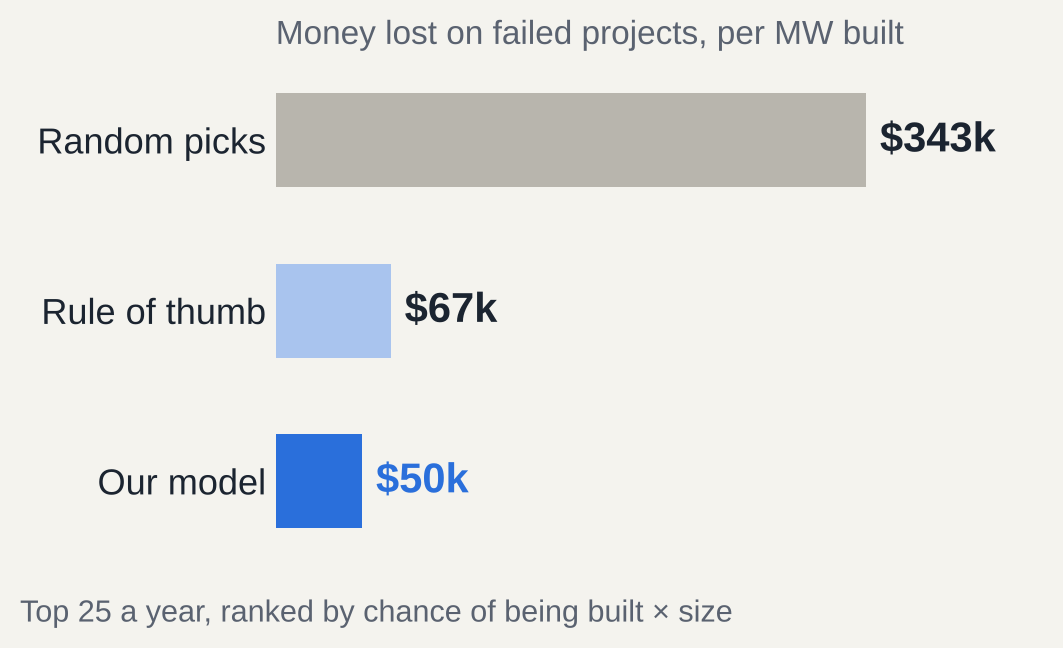

saved reports/figures/15_top25_share_built.png


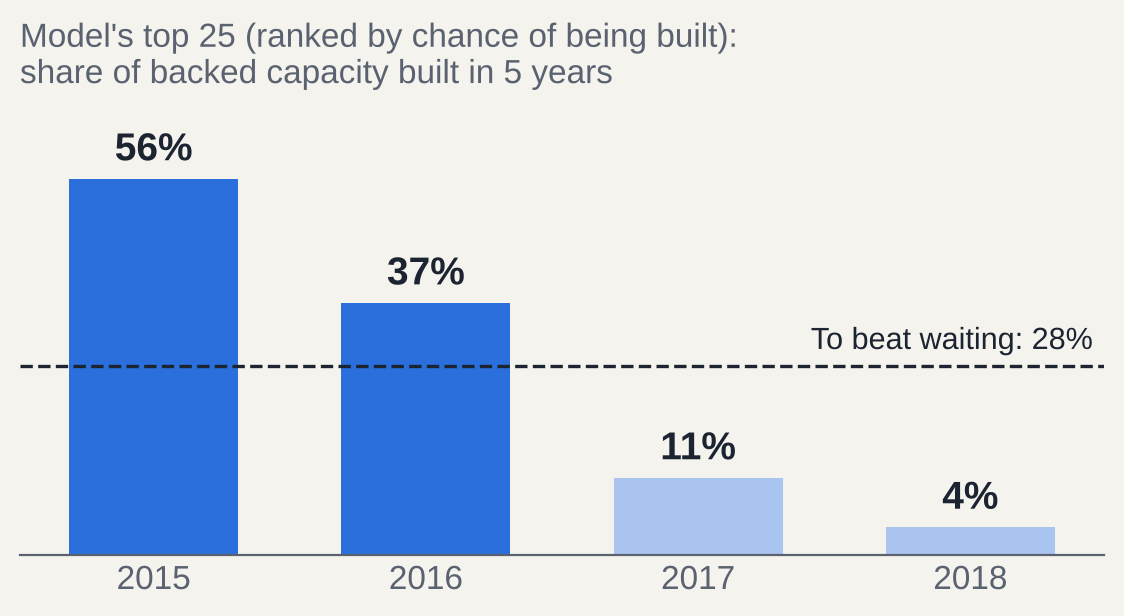

In [7]:
LIGHT, GRAY = "#A9C4EE", "#B8B5AD"

def plain_axes(w, h):
    fig, ax = plt.subplots(figsize=(w, h), facecolor=BG)   # same size as the slide's chart images
    ax.set_facecolor(BG)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    return fig, ax

# Chart 3: money lost per MW built
fig, ax = plain_axes(5.42, 3.27)
names = list(waste)[::-1]
vals = [waste[n] for n in names]
colors = {"Random picks": GRAY, "Rule of thumb": LIGHT, "Our model": BLUE}
ax.barh(names, vals, color=[colors[n] for n in names], height=0.55)
for n, v in zip(names, vals):
    ax.text(v + 8, n, f"${v:.0f}k", va="center", fontsize=15, fontweight="bold",
            color=BLUE if n == "Our model" else INK)
ax.set_xlim(0, max(vals) * 1.3)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", labelsize=13, labelcolor=INK)
ax.set_title("Money lost on failed projects, per MW built", loc="left", fontsize=12, color=MUTED, pad=10)
fig.text(0.02, 0.02, "Top 25 a year, ranked by chance of being built × size", fontsize=11, color=MUTED)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "14_wasted_per_mw.png", dpi=200, facecolor=BG)
print("saved reports/figures/14_wasted_per_mw.png")
plt.show()

# Chart 4: the model's top 25, share of backed capacity built, against the break-even
BREAK_EVEN = 28   # median break-even hit rate across the sourced cost assumptions (strategy.py)
fig, ax = plain_axes(5.81, 3.27)
yrs = [str(t) for t in share]
vs = list(share.values())
ax.bar(yrs, vs, color=[BLUE if v >= BREAK_EVEN else LIGHT for v in vs], width=0.62)
for t, v in zip(yrs, vs):
    ax.text(t, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", fontsize=14, fontweight="bold", color=INK)
ax.axhline(BREAK_EVEN, color=INK, ls="--", lw=1.2)
ax.text(len(yrs) - 0.55, BREAK_EVEN + 1.5, f"To beat waiting: {BREAK_EVEN}%", ha="right", va="bottom", fontsize=11, color=INK)
ax.set_ylim(0, max(vs) * 1.18)
ax.set_yticks([])
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(axis="x", labelsize=12)
ax.set_title("Model's top 25 (ranked by chance of being built):\nshare of backed capacity built in 5 years",
             loc="left", fontsize=12, color=MUTED, pad=10)
fig.tight_layout()
fig.savefig(FIG / "15_top25_share_built.png", dpi=200, facecolor=BG)
print("saved reports/figures/15_top25_share_built.png")
plt.show()

## For the slide

Suggested title: *Queue entries rose almost 5× from 2014 to 2020, while the share built within 5 years fell from 20% to 3%.*

Source line: Berkeley Lab, *Queued Up* (data through end-2025); six grid operators (CAISO, ERCOT, MISO, NYISO, PJM, SPP), clean-energy projects entering 2005–2020.

**Money slide.** Title: *Picking with the model cuts wasted money by about 85%, and early backing pays off when 28% of picks get built.* 2017–2018 fall short because only 4–8% of new capacity was built in those cohorts; the model's top fifth was still built about 2× as often as average. These numbers replace an earlier version of the slide charts made before the Nov 24 odd-row decision (24% and 23% for 2017–2018, rule of thumb $65k).